# LITE ensembles on Beef and PigAirwayPressure (Kaggle, 2 GPUs)

Trains **10 LITE models** (seeds 0–9, original LITE training, 1500 epochs) on each of Beef and PigAirwayPressure, then averages their softmax outputs and reports ensemble accuracy for sizes 1–10, next to the paper's LITETime-k curve (results_ensemble_study.csv).

Original training is used because PigAirwayPressure has only 2 training samples per class, so a validation split is impossible.

Paper: Beef LITE 0.720, LITETime 0.767 · PigAirwayPressure LITE 0.347, LITETime 0.471

20 runs, about **1 h** on GPU T4 ×2.

**Settings:** GPU T4 ×2, Internet On, attach the private `lite_code` dataset (Add Input → Your Datasets).
**Run with Save Version → Save & Run All (Commit).** Download `lite_beefpig_results.zip` from the Output tab.

In [1]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-ac5f650e-c698-aa92-a99d-fb43a6cd96cb)
GPU 1: Tesla T4 (UUID: GPU-7c783607-f6ba-a693-d89a-c789ed15c81f)


## 1. Code and dependencies

In [2]:
import glob, os, shutil
hits = glob.glob("/kaggle/input/**/src/classifiers/lite.py", recursive=True)
assert hits, "Attach the lite_code dataset: Add Input -> Your Datasets"
code_dir = os.path.dirname(os.path.dirname(os.path.dirname(hits[0])))
shutil.copytree(code_dir, "/tmp/lite_code", dirs_exist_ok=True)
print("Code copied from", code_dir)
%cd /tmp/lite_code
!pip install -q aeon codecarbon

Code copied from /kaggle/input/datasets/paramikris/lite-reconstruct
/tmp/lite_code


## 2. `run_ablation.py` (same version as in the repo)

In [3]:
%%writefile run_ablation.py
"""Run a paired LITE ablation without using the test set for model selection."""

import argparse
import csv
import time
from pathlib import Path

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

from src.classifiers import LITE
from src.utils import load_data


class BestEpoch(tf.keras.callbacks.Callback):
    def __init__(self, monitor):
        super().__init__()
        self.monitor = monitor
        self.best_value = float("inf")
        self.best_epoch = 0
        self.epochs_seen = 0

    def on_epoch_end(self, epoch, logs=None):
        self.epochs_seen = epoch + 1
        value = (logs or {}).get(self.monitor)
        if value is not None and value < self.best_value:
            self.best_value = float(value)
            self.best_epoch = epoch + 1


def add_first_difference(x):
    differences = np.diff(x, axis=1, prepend=x[:, :1, :])
    return np.concatenate((x, differences), axis=2)


@tf.keras.utils.register_keras_serializable(package="ablation")
class TimeSeriesAugment(tf.keras.layers.Layer):
    """Training-only augmentation: per-sample amplitude scaling, Gaussian jitter and a
    random circular time shift. Identity at inference, so test predictions are unaffected."""

    def __init__(self, length, scale=0.1, jitter=0.03, max_shift=0.1, **kwargs):
        super().__init__(**kwargs)
        self.length, self.scale, self.jitter, self.max_shift = length, scale, jitter, max_shift

    def call(self, x, training=None):
        if not training:
            return x
        batch = tf.shape(x)[0]
        if self.scale > 0:
            x = x * tf.random.normal([batch, 1, 1], 1.0, self.scale)
        if self.jitter > 0:
            x = x + tf.random.normal(tf.shape(x), 0.0, self.jitter)
        max_steps = int(self.max_shift * self.length)
        if max_steps > 0:
            shifts = tf.random.uniform([batch], -max_steps, max_steps + 1, dtype=tf.int32)
            idx = tf.math.floormod(tf.range(self.length)[None, :] - shifts[:, None], self.length)
            x = tf.gather(x, idx, batch_dims=1)
        return x

    def get_config(self):
        return {**super().get_config(), "length": self.length, "scale": self.scale,
                "jitter": self.jitter, "max_shift": self.max_shift}


def add_augmentation(lite, length, channels, args):
    """Put a TimeSeriesAugment layer in front of the LITE network and recompile as LITE does."""
    inputs = tf.keras.layers.Input((length, channels))
    augmented = TimeSeriesAugment(length, args.aug_scale, args.aug_jitter, args.aug_shift)(inputs)
    lite.model = tf.keras.models.Model(inputs, lite.model(augmented))
    lite.model.compile(loss="categorical_crossentropy", optimizer="Adam", metrics=["accuracy"])


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--datasets", nargs="+", default=["PigAirwayPressure", "SemgHandMovementCh2"])
    parser.add_argument("--seeds", nargs="+", type=int, default=[0, 1, 2, 3, 4])
    parser.add_argument("--epochs", type=int, default=100)
    parser.add_argument("--patience", type=int, default=10)
    parser.add_argument("--val-split", type=float, default=0.2)
    parser.add_argument("--output-dir", type=Path, default=Path("results_ablation"))
    parser.add_argument(
        "--conditions",
        nargs="+",
        choices=["original", "validation", "first_difference", "validation_and_difference",
                 "validation_refit", "augment"],
        default=["original", "validation"],
    )
    parser.add_argument("--aug-scale", type=float, default=0.1, help="sd of per-sample amplitude scaling")
    parser.add_argument("--aug-jitter", type=float, default=0.03, help="sd of additive noise (data is z-normalised)")
    parser.add_argument("--aug-shift", type=float, default=0.1, help="max circular shift as a fraction of length")
    parser.add_argument("--lr-patience", type=int, default=8,
                        help="ReduceLROnPlateau patience (LITE paper uses 50)")
    parser.add_argument("--verbose", type=int, default=0)
    args = parser.parse_args()

    if not 0 < args.val_split < 1:
        parser.error("--val-split must be between 0 and 1")
    if args.epochs < 1 or args.patience < 1:
        parser.error("--epochs and --patience must be positive")

    args.output_dir.mkdir(parents=True, exist_ok=True)
    results_path = args.output_dir / "results_per_run.csv"
    fields = ["dataset", "condition", "seed", "accuracy", "training_seconds", "epochs_run", "best_epoch"]
    # validation_refit: pick the epoch count with early stopping on a validation split,
    # then retrain from scratch on the full training set for that many epochs.
    all_conditions = [
        ("original", False, False),
        ("validation", True, False),
        ("first_difference", False, True),
        ("validation_and_difference", True, True),
        ("validation_refit", True, False),
        ("augment", False, False),
    ]

    # Append so rerunning into an existing output dir never wipes earlier results.
    # Runs already in the CSV are skipped, so an interrupted job can simply be restarted.
    new_file = not results_path.exists()
    done = set()
    if not new_file:
        with results_path.open(newline="") as existing:
            done = {(r["dataset"], r["condition"], int(r["seed"])) for r in csv.DictReader(existing)}
    with results_path.open("a", newline="") as results_file:
        writer = csv.DictWriter(results_file, fieldnames=fields)
        if new_file:
            writer.writeheader()
        results_file.flush()

        for dataset in args.datasets:
            x_train, y_train, x_test, y_test = load_data(file_name=dataset)
            for seed in args.seeds:
                for condition, use_validation, use_difference in all_conditions:
                    if condition not in args.conditions:
                        continue
                    if (dataset, condition, seed) in done:
                        print(f"{dataset} | {condition} | seed={seed} | already done, skipping", flush=True)
                        continue
                    print(f"{time.strftime('%H:%M:%S')} start {dataset} | {condition} | seed={seed}", flush=True)
                    tf.keras.utils.set_random_seed(seed)
                    if use_validation:
                        x_fit, x_val, y_fit, y_val = train_test_split(
                            x_train, y_train, test_size=args.val_split,
                            random_state=seed, stratify=y_train,
                        )
                    else:
                        x_fit, y_fit = x_train, y_train
                        x_val, y_val = None, None

                    if use_difference:
                        x_fit = add_first_difference(x_fit)
                        x_test_run = add_first_difference(x_test)
                        if x_val is not None:
                            x_val = add_first_difference(x_val)
                    else:
                        x_test_run = x_test

                    run_dir = args.output_dir / dataset / condition / f"seed_{seed}"
                    run_dir.mkdir(parents=True, exist_ok=True)
                    monitor = "val_loss" if use_validation else "loss"
                    epoch_tracker = BestEpoch(monitor)
                    model = LITE(
                        output_directory=f"{run_dir}/", length_TS=x_fit.shape[1],
                        n_channels=x_fit.shape[2], n_classes=len(np.unique(y_train)),
                        n_epochs=args.epochs, verbose=args.verbose,
                    )
                    if condition == "augment":
                        add_augmentation(model, x_fit.shape[1], x_fit.shape[2], args)
                    callbacks = [
                        tf.keras.callbacks.ReduceLROnPlateau(
                            monitor=monitor, factor=0.5, patience=args.lr_patience, min_lr=1e-4
                        ),
                        tf.keras.callbacks.ModelCheckpoint(
                            filepath=str(run_dir / "best_model.keras"),
                            monitor=monitor, save_best_only=True,
                        ),
                        epoch_tracker,
                    ]
                    if use_validation:
                        callbacks.append(tf.keras.callbacks.EarlyStopping(
                            monitor="val_loss", patience=args.patience,
                            restore_best_weights=True,
                        ))
                    model.callbacks = callbacks

                    started = time.perf_counter()
                    model.fit(
                        xtrain=x_fit, ytrain=y_fit, xval=x_val, yval=y_val,
                        plot_test=use_validation,
                    )
                    epochs_run = epoch_tracker.epochs_seen
                    best_epoch = epoch_tracker.best_epoch

                    if condition == "validation_refit":
                        tf.keras.utils.set_random_seed(seed)
                        refit_dir = run_dir / "refit"
                        refit_dir.mkdir(parents=True, exist_ok=True)
                        model = LITE(
                            output_directory=f"{refit_dir}/", length_TS=x_train.shape[1],
                            n_channels=x_train.shape[2], n_classes=len(np.unique(y_train)),
                            n_epochs=best_epoch, verbose=args.verbose,
                        )
                        model.callbacks = [
                            tf.keras.callbacks.ReduceLROnPlateau(
                                monitor="loss", factor=0.5, patience=args.lr_patience, min_lr=1e-4
                            ),
                            tf.keras.callbacks.ModelCheckpoint(
                                filepath=str(refit_dir / "best_model.keras"),
                                monitor="loss", save_best_only=True,
                            ),
                        ]
                        model.fit(xtrain=x_train, ytrain=y_train, plot_test=False)
                        epochs_run += best_epoch

                    training_seconds = time.perf_counter() - started
                    _, accuracy, _ = model.predict(xtest=x_test_run, ytest=y_test)
                    writer.writerow({
                        "dataset": dataset, "condition": condition, "seed": seed,
                        "accuracy": accuracy, "training_seconds": training_seconds,
                        "epochs_run": epochs_run,
                        "best_epoch": best_epoch,
                    })
                    results_file.flush()
                    print(f"{dataset} | {condition} | seed={seed} | accuracy={accuracy:.4f} | epochs={epoch_tracker.best_epoch}")


if __name__ == "__main__":
    main()

Overwriting run_ablation.py


## 3. Settings

Each job is (dataset, run name, seed, flags).

In [4]:
EPOCHS = 1500
LR_PATIENCE = 50
OUT = "/kaggle/working/ensemble_beef_pig"
JOBS = [
    ('PigAirwayPressure', 'original', 0, '--conditions original'),
    ('PigAirwayPressure', 'original', 1, '--conditions original'),
    ('PigAirwayPressure', 'original', 2, '--conditions original'),
    ('PigAirwayPressure', 'original', 3, '--conditions original'),
    ('PigAirwayPressure', 'original', 4, '--conditions original'),
    ('PigAirwayPressure', 'original', 5, '--conditions original'),
    ('PigAirwayPressure', 'original', 6, '--conditions original'),
    ('PigAirwayPressure', 'original', 7, '--conditions original'),
    ('PigAirwayPressure', 'original', 8, '--conditions original'),
    ('PigAirwayPressure', 'original', 9, '--conditions original'),
    ('Beef', 'original', 0, '--conditions original'),
    ('Beef', 'original', 1, '--conditions original'),
    ('Beef', 'original', 2, '--conditions original'),
    ('Beef', 'original', 3, '--conditions original'),
    ('Beef', 'original', 4, '--conditions original'),
    ('Beef', 'original', 5, '--conditions original'),
    ('Beef', 'original', 6, '--conditions original'),
    ('Beef', 'original', 7, '--conditions original'),
    ('Beef', 'original', 8, '--conditions original'),
    ('Beef', 'original', 9, '--conditions original'),
]

# To continue an interrupted version: Add Input -> previous version of this notebook, then set e.g.
# RESUME_FROM = "/kaggle/input/<notebook-name>/ensemble_beef_pig"
RESUME_FROM = ""

if RESUME_FROM and os.path.isdir(RESUME_FROM) and not os.path.exists(OUT):
    shutil.copytree(RESUME_FROM, OUT); print("Resumed from", RESUME_FROM)
os.makedirs(OUT, exist_ok=True); print("Saving to", OUT, "|", len(JOBS), "jobs")

Saving to /kaggle/working/ensemble_beef_pig | 20 jobs


## 4. Smoke test (~1 min)

In [5]:
d, _, _, f = JOBS[-1]
!python -u run_ablation.py --datasets {d} --seeds 0 --epochs 2 {f} --output-dir /tmp/smoke
!cat /tmp/smoke/results_per_run.csv && rm -rf /tmp/smoke

20:10:19 start Beef | original | seed=0
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Beef | original | seed=0 | accuracy=0.1667 | epochs=2




## 5. Run all jobs on both GPUs

Both GPUs pull from one shared queue (longest jobs first). Each run writes to `OUT/<dataset>/<run>/seed_<n>/`. Finished runs are skipped on resume. Progress is printed every 5 minutes.

In [6]:
import queue, subprocess, threading, time

tasks = queue.Queue()
for job in JOBS:
    tasks.put(job)
total = tasks.qsize()
finished, lock = [], threading.Lock()

def worker(gpu):
    env = {**os.environ, "CUDA_VISIBLE_DEVICES": str(gpu), "TF_CPP_MIN_LOG_LEVEL": "2"}
    while True:
        try:
            dataset, name, seed, flags = tasks.get_nowait()
        except queue.Empty:
            return
        out_dir = f"{OUT}/{dataset}/{name}/seed_{seed}"
        cmd = (f"python -u run_ablation.py --datasets {dataset} --seeds {seed} {flags} "
               f"--epochs {EPOCHS} --lr-patience {LR_PATIENCE} --output-dir {out_dir} --verbose 0")
        os.makedirs(out_dir, exist_ok=True)
        with open(f"{out_dir}/run.log", "a") as log:
            rc = subprocess.call(cmd, shell=True, env=env, stdout=log, stderr=subprocess.STDOUT)
        with lock:
            finished.append(f"{time.strftime('%H:%M:%S')} gpu{gpu} {dataset} {name} seed={seed} exit={rc}")

threads = [threading.Thread(target=worker, args=(g,)) for g in (0, 1)]
for t in threads: t.start()
while any(t.is_alive() for t in threads):
    time.sleep(300)
    with lock:
        print(f"{time.strftime('%H:%M:%S')}  {len(finished)}/{total} done", *finished[-2:], sep="\n    ")
print("all done:", *finished, sep="\n    ")

20:15:46  0/20 done
20:20:46  1/20 done
    20:20:38 gpu1 PigAirwayPressure original seed=1 exit=0
20:25:46  2/20 done
    20:20:38 gpu1 PigAirwayPressure original seed=1 exit=0
    20:20:55 gpu0 PigAirwayPressure original seed=0 exit=0
20:30:46  4/20 done
    20:30:00 gpu1 PigAirwayPressure original seed=2 exit=0
    20:30:40 gpu0 PigAirwayPressure original seed=3 exit=0
20:35:46  4/20 done
    20:30:00 gpu1 PigAirwayPressure original seed=2 exit=0
    20:30:40 gpu0 PigAirwayPressure original seed=3 exit=0
20:40:46  6/20 done
    20:40:10 gpu1 PigAirwayPressure original seed=4 exit=0
    20:40:26 gpu0 PigAirwayPressure original seed=5 exit=0
20:45:46  6/20 done
    20:40:10 gpu1 PigAirwayPressure original seed=4 exit=0
    20:40:26 gpu0 PigAirwayPressure original seed=5 exit=0
20:50:46  8/20 done
    20:49:44 gpu0 PigAirwayPressure original seed=7 exit=0
    20:49:51 gpu1 PigAirwayPressure original seed=6 exit=0
20:55:46  8/20 done
    20:49:44 gpu0 PigAirwayPressure original seed=7 e

## 6. Single-model results

In [7]:
import pandas as pd
from pathlib import Path
rows = []
for path in glob.glob(f"{OUT}/*/*/seed_*/results_per_run.csv"):
    df = pd.read_csv(path); df["run"] = Path(path).parts[-3]; rows.append(df)
res = pd.concat(rows, ignore_index=True).sort_values(["dataset", "run", "seed"])
res.to_csv(f"{OUT}/all_runs.csv", index=False)
display(res.pivot_table(index=["dataset", "seed"], columns="run", values="accuracy").round(4))
display(res.groupby(["dataset", "run"]).accuracy.agg(["mean", "median", "std", "count"]).round(4))

run                     original
dataset           seed          
Beef              0       0.7333
                  1       0.7000
                  2       0.6667
                  3       0.7667
                  4       0.7333
                  5       0.7667
                  6       0.7000
                  7       0.7667
                  8       0.7667
                  9       0.7667
PigAirwayPressure 0       0.3750
                  1       0.3942
                  2       0.0673
                  3       0.0865
                  4       0.3413
                  5       0.4279
                  6       0.4663
                  7       0.3702
                  8       0.3990
                  9       0.3654

,,mean,median,std,count
dataset,run,,,,
Beef,original,0.7367,0.7500,0.0367,10
PigAirwayPressure,original,0.3293,0.3726,0.1376,10


## 7. Ensembles vs the paper

For each run type with 2+ models: average the softmax outputs of k models. For each k, accuracy is averaged over 200 random subsets of k models. `all` is the ensemble of every model. The paper's LITETime-k values come from `results_ensemble_study.csv`.

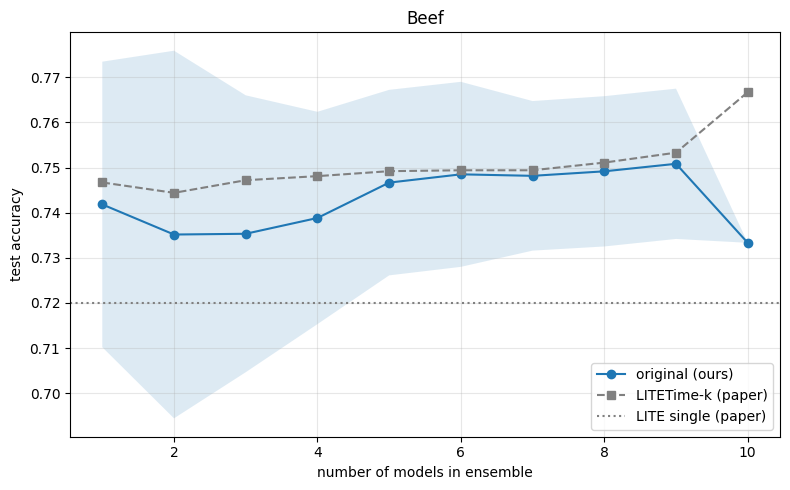

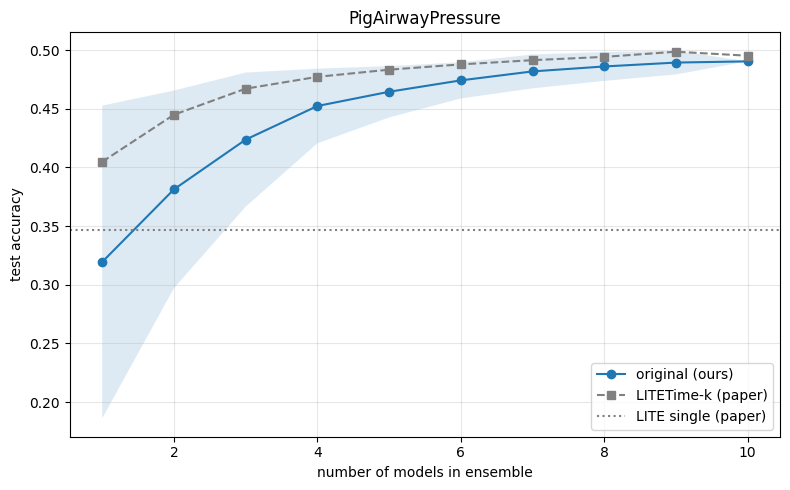

dataset,Beef,PigAirwayPressure
run,original,original
k,,
1,0.7418,0.3194
2,0.7352,0.3813
3,0.7353,0.4237
4,0.7388,0.4523
5,0.7467,0.4645
6,0.7485,0.4742
7,0.7482,0.4818
8,0.7492,0.4860


,dataset,run,seeds,mean_single,ensemble_all,paper_LITE,paper_LITETime
0,Beef,original,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.7367,0.7333,0.720,0.767
1,PigAirwayPressure,original,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.3293,0.4904,0.347,0.471


In [8]:
import numpy as np, tensorflow as tf, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from src.utils import load_data
import run_ablation  # registers the augmentation layer so augmented checkpoints load (it is identity at test time)

PAPER = {  # LITE, LITETime (5 models), LITETime-k for k = 1..10
    "PigAirwayPressure": (0.347, 0.471, [0.4048, 0.4449, 0.4671, 0.4772, 0.4833, 0.4878, 0.4914, 0.4942, 0.4986, 0.4952]),
    "Beef": (0.720, 0.767, [0.7467, 0.7444, 0.7472, 0.7481, 0.7492, 0.7494, 0.7494, 0.7511, 0.7533, 0.7667]),
    "SemgHandMovementCh2": (0.479, 0.511, [0.4667, 0.4982, 0.5139, 0.5247, 0.5315, 0.5369, 0.5404, 0.5458, 0.5507, 0.5511]),
}
rng = np.random.default_rng(0)
curves, summary = [], []
for dataset in sorted({j[0] for j in JOBS}):
    _, _, x_test, y_test = load_data(file_name=dataset)
    plt.figure(figsize=(8, 5))
    for name in sorted({j[1] for j in JOBS if j[0] == dataset}):
        probs = {}
        for ckpt in glob.glob(f"{OUT}/{dataset}/{name}/seed_*/{dataset}/*/seed_*/best_model.keras"):
            seed = int(Path(ckpt).parts[-2][5:])
            probs[seed] = tf.keras.models.load_model(ckpt, compile=False).predict(x_test, verbose=0)
            tf.keras.backend.clear_session()
        if len(probs) < 2:
            continue
        seeds = sorted(probs)
        for k in range(1, len(seeds) + 1):
            accs = [accuracy_score(y_test, np.mean([probs[s] for s in rng.choice(seeds, k, replace=False)], 0).argmax(1))
                    for _ in range(200)]
            curves.append({"dataset": dataset, "run": name, "k": k, "mean_acc": np.mean(accs), "std": np.std(accs)})
        all_acc = accuracy_score(y_test, np.mean([probs[s] for s in seeds], 0).argmax(1))
        singles = [accuracy_score(y_test, probs[s].argmax(1)) for s in seeds]
        summary.append({"dataset": dataset, "run": name, "seeds": seeds, "mean_single": np.mean(singles),
                        "ensemble_all": all_acc, "paper_LITE": PAPER[dataset][0], "paper_LITETime": PAPER[dataset][1]})
        c = pd.DataFrame([r for r in curves if r["dataset"] == dataset and r["run"] == name])
        plt.plot(c.k, c.mean_acc, "o-", label=f"{name} (ours)")
        plt.fill_between(c.k, c.mean_acc - c["std"], c.mean_acc + c["std"], alpha=0.15)
    plt.plot(range(1, 11), PAPER[dataset][2], "s--", color="gray", label="LITETime-k (paper)")
    plt.axhline(PAPER[dataset][0], color="gray", ls=":", label="LITE single (paper)")
    plt.xlabel("number of models in ensemble"); plt.ylabel("test accuracy"); plt.title(dataset)
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(f"{OUT}/ensemble_{dataset}.png", dpi=150); plt.show()

pd.DataFrame(curves).to_csv(f"{OUT}/ensemble_curves.csv", index=False)
summary = pd.DataFrame(summary); summary.to_csv(f"{OUT}/ensemble_summary.csv", index=False)
display(pd.DataFrame(curves).pivot_table(index="k", columns=["dataset", "run"], values="mean_acc").round(4))
display(summary.round(4))

## 8. Zip results (CSVs, logs, plots and checkpoints)

In [9]:
!cd {OUT} && zip -q -r /kaggle/working/lite_beefpig_results.zip .
!ls -lh /kaggle/working/lite_beefpig_results.zip

-rw-r--r-- 1 root root 3.2M Nov 12 21:31 /kaggle/working/lite_beefpig_results.zip
